# 2. Binary classification performance

Does each detector report the action unit that was animated?

Reads the tables notebook 1 wrote, checks whether the AUC exceeds
chance, compares the detectors against each other, and asks whether
performance varies by avatar and by animation. The distributions are
checked for normality first, which is what decides between the
parametric and the rank-based test in each comparison.

Produces Figure 2 and Supplementary Figure 1.

In [1]:
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns

from au_detection_mh import analyses, utils

DATASET = os.path.join("..", "ds-au_detection_mh")
SOURCEDATA = os.path.join(DATASET, "sourcedata")
LANDMARKS = os.path.join(DATASET, "derivatives", "landmark-displacement")
RESULTS = os.path.join(DATASET, "derivatives", "au-detection-metrics")

# Activation above which a cell of the rig ground truth counts as an
# active action unit, and above which a detector counts as reporting
# one.  0.2 is the value the reported results use.
THRESHOLD = 0.2

# Avatar order used in the figures, which groups the two avatars the
# detectors did best on next to each other.
AVATAR_ORDER = ["Ada", "Pia", "Cooper", "Garry"]

# Manuscript figure styling
LABEL_FONTSIZE = 12
TICK_FONTSIZE = 10
DPI = 500
mpl.rcParams["font.size"] = 10

## Reading the tables

In [2]:
def read_table(detector):
    name = (f"{detector}_classification_metrics_all_"
            f"threshold_{THRESHOLD}.csv")
    return pd.read_csv(os.path.join(RESULTS, name), index_col=0)


df_OF_all = read_table("OF")
df_AFAR_all = read_table("AFAR")
df_pyFEAT_all = read_table("pyFEAT")

n_videos = len(df_OF_all)

# OpenFace and AFAR are the two detectors the reported comparisons are
# between; df_three adds py-feat for the supplementary figure.
df_comb = pd.concat([df_OF_all, df_AFAR_all], ignore_index=True)
df_comb["model"] = np.repeat(["OF", "AFAR"], n_videos)

df_three = pd.concat(
    [df_OF_all, df_AFAR_all, df_pyFEAT_all], ignore_index=True)
df_three["model"] = np.repeat(["OF", "AFAR", "pyFeat"], n_videos)

DVS = ["AUC", "TPR", "FPR"]
df_comb[DVS].describe().map("{:,.2f}".format)

,AUC,TPR,FPR
count,144.00,144.00,144.00
mean,0.69,0.31,0.10
std,0.20,0.30,0.10
min,0.22,0.00,0.00
25%,0.56,0.00,0.01
50%,0.70,0.27,0.08
75%,0.82,0.51,0.13
max,1.00,1.00,0.50


### Supplementary Figure 1: all three detectors

py-feat is shown here rather than in Figure 2 because it detected an
action unit in almost every frame, which puts its false positive rate
far above the other two and makes a three-way comparison of the rates
uninformative.

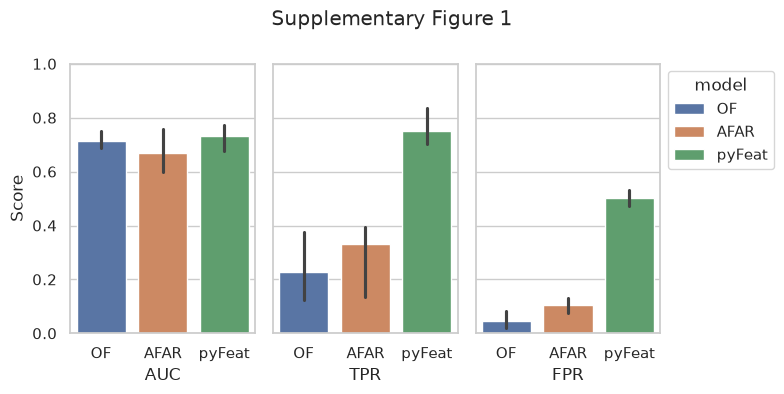

In [3]:
sns.set(rc={"axes.facecolor": "white", "figure.facecolor": "white"})
sns.set_style("whitegrid")

fig, axs = plt.subplots(1, len(DVS), sharex=False, sharey=True,
                        figsize=(8, 4))
for index, dv in enumerate(DVS):
    show_legend = index == len(DVS) - 1
    ax = sns.barplot(df_three, x="model", y=dv, hue="model",
                     estimator="median", errorbar="ci", ax=axs[index],
                     legend=True if show_legend else None)
    if show_legend:
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    axs[index].set_ylim(0, 1)
    axs[index].set_xlabel(dv)
    axs[index].set_ylabel("Score")
plt.suptitle("Supplementary Figure 1")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS, "suppl-fig-1.svg"), dpi=DPI)
plt.show()

In [4]:
df_three[df_three["model"] == "pyFeat"][DVS].describe()

,AUC,TPR,FPR
count,72.000000,72.000000,72.000000
mean,0.662890,0.689103,0.519063
std,0.245200,0.330959,0.105728
min,0.012966,0.000000,0.304700
25%,0.598206,0.606286,0.437894
50%,0.733387,0.751677,0.500810
75%,0.815287,1.000000,0.587520
max,0.997776,1.000000,0.783626


## Checking the normality assumption

A histogram and a Q-Q plot per detector and measure, with the
Shapiro-Wilk statistic annotated. Where the measure is not normally
distributed, the comparisons below use a rank-based test.

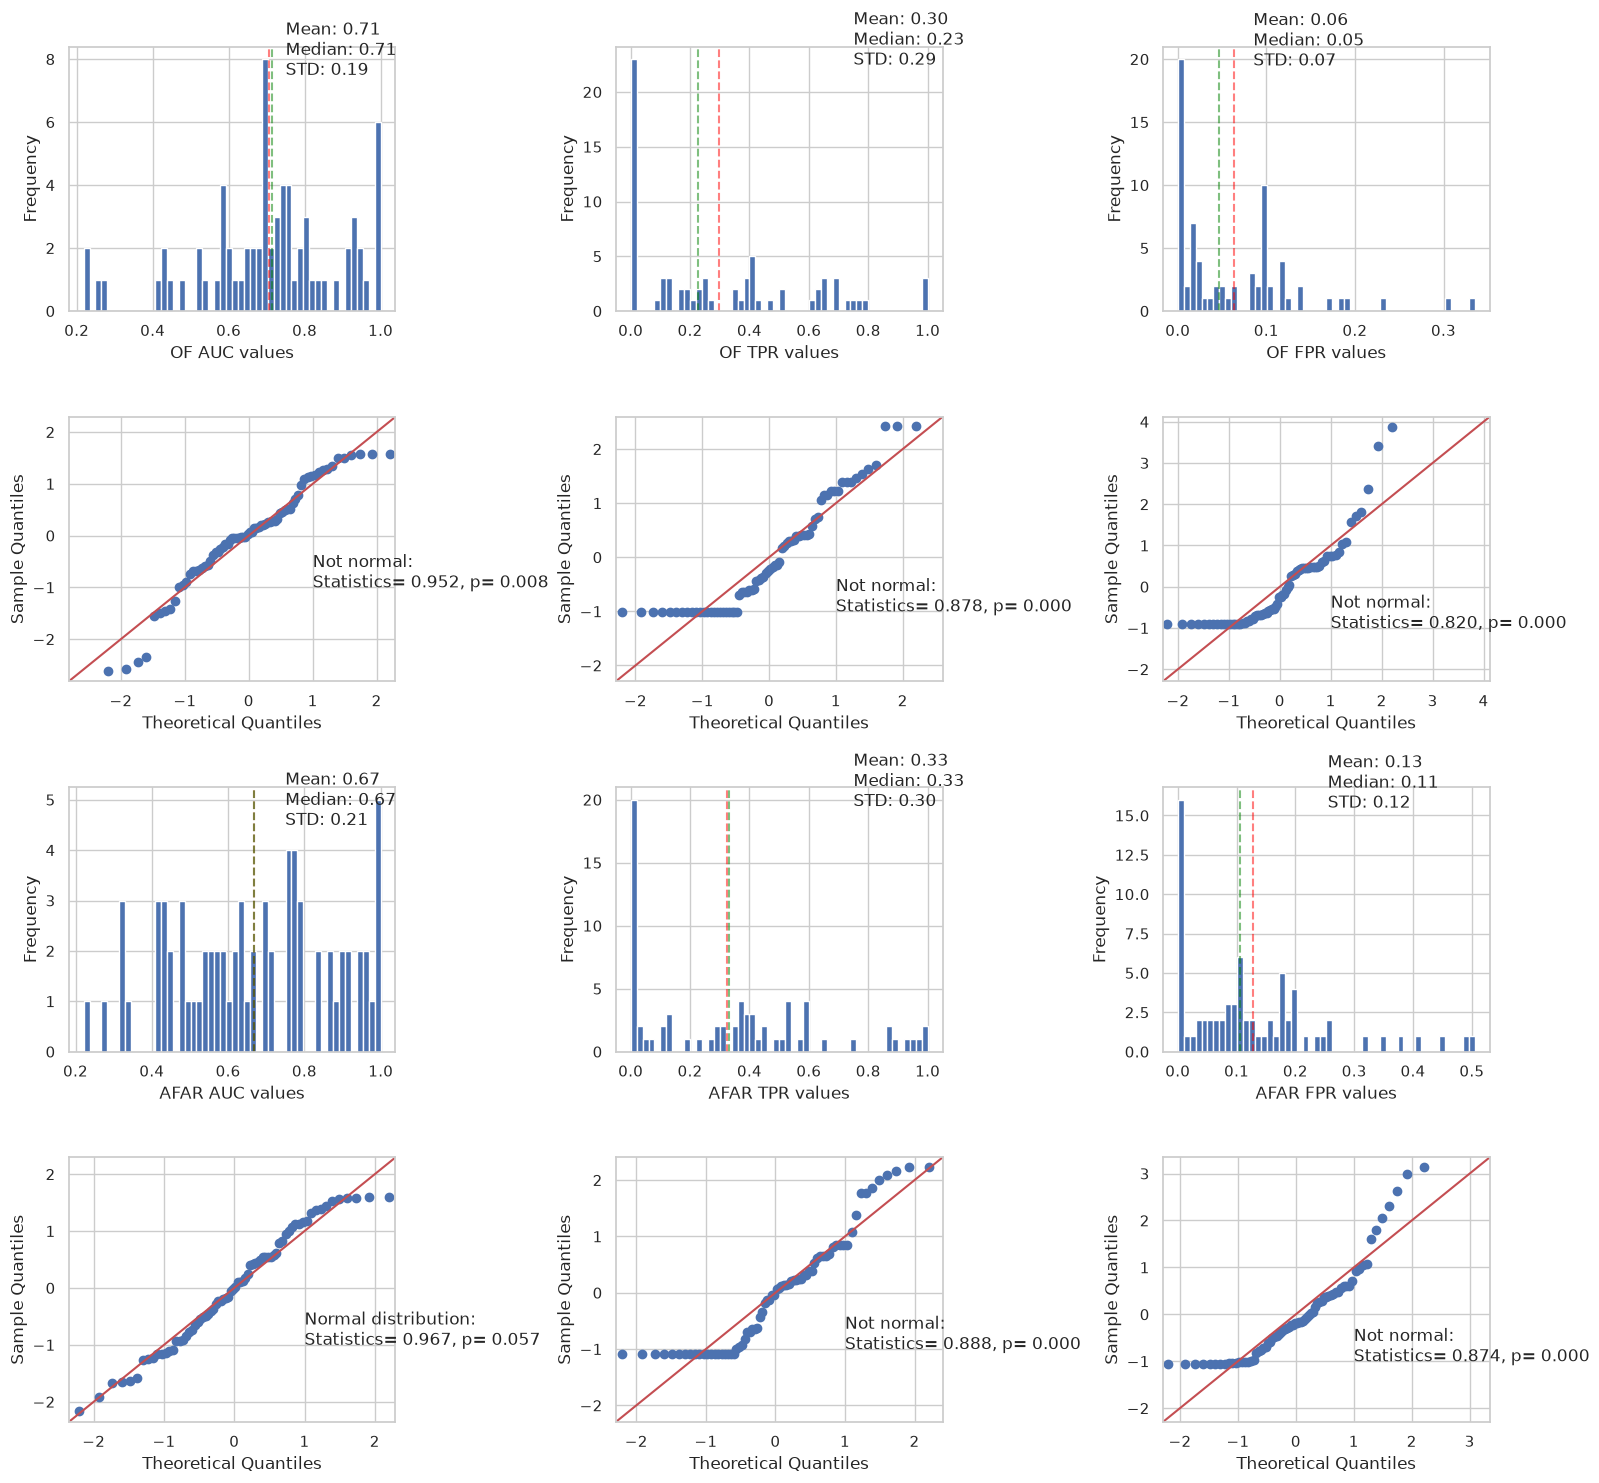

In [5]:
import statsmodels.api as sm
from scipy.stats import shapiro

ALPHA = 0.05
panels = [("OF", df_OF_all), ("AFAR", df_AFAR_all)]

fig, axs = plt.subplots(2 * len(panels), len(DVS), figsize=(16, 15))
for column, dv in enumerate(DVS):
    for panel, (detector, table) in enumerate(panels):
        values = table[dv].to_numpy()
        hist_row, qq_row = 2 * panel, 2 * panel + 1

        counts, bins = np.histogram(values, bins=50)
        axs[hist_row, column].hist(values, bins=50)
        axs[hist_row, column].set_xlabel(f"{detector} {dv} values")
        axs[hist_row, column].set_ylabel("Frequency")
        axs[hist_row, column].axvline(np.mean(values), linestyle="dashed",
                                      color="red", alpha=0.5)
        axs[hist_row, column].axvline(np.median(values), linestyle="dashed",
                                      color="green", alpha=0.5)
        axs[hist_row, column].annotate(
            f"Mean: {np.mean(values):.2f}\n"
            f"Median: {np.median(values):.2f}\n"
            f"STD: {np.std(values):.2f}",
            xy=(max(bins) - 0.25, max(counts) - 0.5))

        standardised = (values - np.mean(values)) / np.std(values)
        sm.qqplot(standardised, line="45", ax=axs[qq_row, column])
        statistic, p_value = shapiro(values)
        verdict = ("Normal distribution"
                   if p_value > ALPHA else "Not normal")
        axs[qq_row, column].annotate(
            f"{verdict}:\nStatistics= {statistic:.3f}, "
            f"p= {p_value:.3f}", xy=(1, -1))

fig.tight_layout()
plt.show()

In [6]:
# Equal variance, the remaining ANOVA assumption for the AUC
pg.homoscedasticity([df_OF_all["AUC"].to_numpy(),
                     df_AFAR_all["AUC"].to_numpy(),
                     df_pyFEAT_all["AUC"].to_numpy()])

,W,pval,equal_var
levene,1.563848,0.211723,True


### AUC: greater than chance?

In [7]:
CHANCE_LEVEL = 0.50
pg.ttest(df_comb["AUC"].values, CHANCE_LEVEL)

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,11.294837,143,two-sided,1.519248e-21,"[0.65, 0.72]",0.941236,1.0,2.983e+18


### AUC: between-detector comparison

In [8]:
factors = ["avatar", "animation", "AUC", "model"]
df_comb[factors].groupby("model").describe().map("{:,.2f}".format)

AUC                                          
       count  mean   std   min   25%   50%   75%   max
model                                                 
AFAR   72.00  0.67  0.21  0.22  0.50  0.67  0.83  1.00
OF     72.00  0.71  0.19  0.22  0.60  0.71  0.81  1.00

In [9]:
pg.ttest(df_comb[df_comb["model"] == "OF"]["AUC"].values,
         df_comb[df_comb["model"] == "AFAR"]["AUC"].values,
         paired=True)

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,1.391985,71,two-sided,0.168272,"[-0.02, 0.09]",0.185714,0.342802,0.326


### AUC: within-factor comparisons

In [10]:
pg.rm_anova(dv="AUC", within="avatar", subject="model", data=df_comb,
            detailed=True, effsize="np2").round(3)

,Source,SS,DF,MS,F,p_unc,np2,eps
0,avatar,0.001,3,0.0,0.975,0.508,0.494,0.333
1,Error,0.001,3,0.0,NaN,NaN,NaN,NaN


In [11]:
pg.rm_anova(dv="AUC", within="animation", subject="model", data=df_comb,
            detailed=True, effsize="np2").round(3)

,Source,SS,DF,MS,F,p_unc,np2,eps
0,animation,0.69,17,0.041,2.303,0.047,0.697,0.059
1,Error,0.30,17,0.018,NaN,NaN,NaN,NaN


### TPR and FPR: between-detector comparisons

In [12]:
rate_factors = ["avatar", "animation", "TPR", "FPR", "model"]
df_comb[rate_factors].groupby("model").describe().map("{:,.2f}".format)

TPR                                              FPR              \
       count  mean   std   min   25%   50%   75%   max  count  mean   std   
model                                                                       
AFAR   72.00  0.33  0.30  0.00  0.00  0.33  0.52  1.00  72.00  0.13  0.12   
OF     72.00  0.30  0.29  0.00  0.00  0.23  0.47  1.00  72.00  0.06  0.07   

                                     
        min   25%   50%   75%   max  
model                                
AFAR   0.00  0.03  0.11  0.18  0.50  
OF     0.00  0.00  0.05  0.10  0.34

In [13]:
RATES = ["TPR", "FPR"]
print(f"Wilcoxon signed-rank test for threshold: {THRESHOLD}")
for rate in RATES:
    scores_of = df_comb[df_comb["model"] == "OF"][rate].values
    scores_afar = df_comb[df_comb["model"] == "AFAR"][rate].values
    print(f"\n{rate}")
    print(pg.wilcoxon(scores_of, scores_afar))

Wilcoxon signed-rank test for threshold: 0.2

TPR
          W_val alternative     p_val       RBC      CLES
Wilcoxon  752.0   two-sided  0.425174 -0.120982  0.471644

FPR
          W_val alternative         p_val      RBC      CLES
Wilcoxon  304.5   two-sided  4.100765e-08 -0.75493  0.330633


### TPR and FPR: within-factor comparisons

Friedman's test across avatars, then across animations, with the
Bonferroni-corrected threshold reported alongside the uncorrected
p-value.

In [14]:
def friedman_within(data, dv, within, subject):
    result = pg.friedman(data=data, dv=dv, within=within,
                         subject=subject)
    corrected = 0.05 / len(data[within].unique())
    print(f"Friedman's test for {dv} across {within}:")
    print(result)
    print(f"Less than the corrected p-val (p/N = {corrected:.4f})? = "
          f"{result['p_unc'].values[0] < corrected}\n")
    return result


for rate in RATES:
    friedman_within(df_comb, rate, "avatar", "animation")

Friedman's test for TPR across avatar:
          Source         W  ddof1          Q     p_unc
Friedman  avatar  0.378407      3  20.433962  0.000138
Less than the corrected p-val (p/N = 0.0125)? = True

Friedman's test for FPR across avatar:
          Source        W  ddof1          Q         p_unc
Friedman  avatar  0.79671      3  43.022346  2.434263e-09
Less than the corrected p-val (p/N = 0.0125)? = True



In [15]:
for rate in RATES:
    friedman_within(df_comb, rate, "animation", "avatar")

Friedman's test for TPR across animation:
             Source         W  ddof1         Q    p_unc
Friedman  animation  0.658883     17  44.80407  0.00026
Less than the corrected p-val (p/N = 0.0028)? = True

Friedman's test for FPR across animation:
             Source         W  ddof1          Q     p_unc
Friedman  animation  0.757484     17  51.508903  0.000025
Less than the corrected p-val (p/N = 0.0028)? = True



In [16]:
df_comb.groupby(["model", "animation"])[RATES].describe()

TPR                                                    \
                count      mean       std       min       25%       50%   
model animation                                                           
AFAR  AU01        4.0  0.476744  0.326963  0.000000  0.436047  0.581395   
      AU02        4.0  0.104651  0.209302  0.000000  0.000000  0.000000   
      AU04        4.0  0.470930  0.545851  0.000000  0.000000  0.441860   
      AU06        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU07        4.0  0.122093  0.214303  0.000000  0.000000  0.023256   
      AU10        4.0  0.145349  0.290698  0.000000  0.000000  0.000000   
      AU12        4.0  0.360465  0.238301  0.023256  0.302326  0.418605   
      AU14        4.0  0.674419  0.281642  0.348837  0.488372  0.697674   
      AU15        4.0  0.459302  0.532477  0.000000  0.000000  0.430233   
      AU17        4.0  0.142857  0.285714  0.000000  0.000000  0.000000   
      AU23        4.0  0.703488  0.308742  0.372093  0.476744  0.720930   
      browsAU10   4.0  0.260204  0.108613  0.136054  0.202381  0.255102   
      browsAU12   4.0  0.420068  0.070559  0.367347  0.382653  0.394558   
      browsAU14   4.0  0.462585  0.140407  0.346939  0.362245  0.425170   
      browsAU15   4.0  0.273810  0.235874  0.034014  0.095238  0.268707   
      browsAU17   4.0  0.215035  0.132974  0.076923  0.118881  0.209790   
      browsAU23   4.0  0.331633  0.169603  0.129252  0.236395  0.336735   
      browsAll    4.0  0.234375  0.096413  0.114583  0.177083  0.255208   
OF    AU01        4.0  0.180233  0.165944  0.000000  0.069767  0.174419   
      AU02        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU04        4.0  0.383721  0.443489  0.000000  0.000000  0.372093   
      AU06        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU07        4.0  0.906977  0.186047  0.627907  0.906977  1.000000   
      AU10        4.0  0.598837  0.261305  0.209302  0.575581  0.709302   
      AU12        4.0  0.627907  0.080561  0.511628  0.616279  0.651163   
      AU14        4.0  0.645349  0.039717  0.604651  0.622093  0.639535   
      AU15        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU17        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU23        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      browsAU10   4.0  0.433673  0.064387  0.353741  0.399660  0.438776   
      browsAU12   4.0  0.399660  0.021779  0.380952  0.380952  0.397959   
      browsAU14   4.0  0.404762  0.011783  0.387755  0.403061  0.408163   
      browsAU15   4.0  0.181973  0.076839  0.108844  0.119048  0.183673   
      browsAU17   4.0  0.160839  0.053866  0.111888  0.122378  0.150350   
      browsAU23   4.0  0.159864  0.053995  0.108844  0.119048  0.153061   
      browsAll    4.0  0.242187  0.081301  0.166667  0.182292  0.229167   

                                      FPR                                \
                      75%       max count      mean       std       min   
model animation                                                           
AFAR  AU01       0.622093  0.744186   4.0  0.114668  0.134417  0.000000   
      AU02       0.104651  0.418605   4.0  0.066045  0.048521  0.001621   
      AU04       0.912791  1.000000   4.0  0.035251  0.050432  0.000000   
      AU06       0.000000  0.000000   4.0  0.101297  0.110453  0.003241   
      AU07       0.145349  0.441860   4.0  0.082253  0.074241  0.000000   
      AU10       0.145349  0.581395   4.0  0.126418  0.045918  0.071313   
      AU12       0.476744  0.581395   4.0  0.284036  0.093183  0.171799   
      AU14       0.883721  0.953488   4.0  0.129660  0.084372  0.029173   
      AU15       0.889535  0.976744   4.0  0.085900  0.076364  0.000000   
      AU17       0.142857  0.571429   4.0  0.094000  0.087376  0.004800   
      AU23       0.947674  1.000000   4.0  0.044571  0.061595  0.000000   
      browsAU10  0.312925  0.394558   4.0 

### Figure 2: AUC heatmaps, and the rates across avatars and animations

The dashed line separates the 11 single-action-unit animations from the
7 brow combinations.

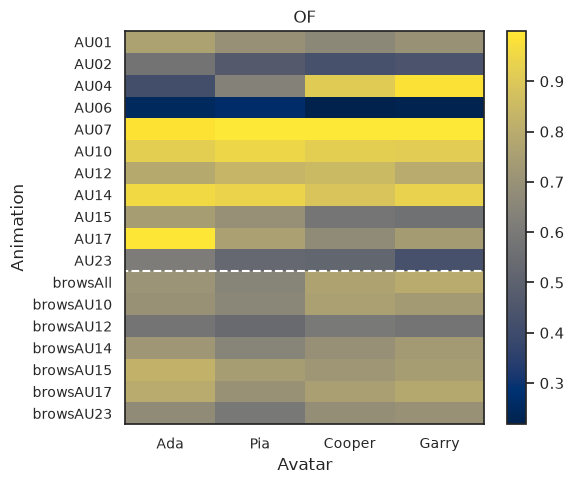

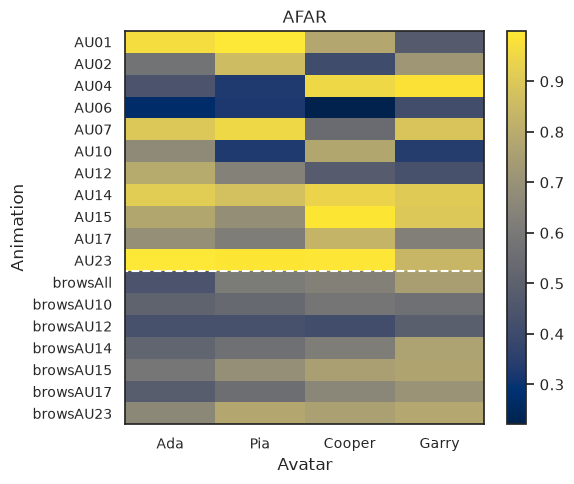

In [17]:
sns.reset_defaults()
sns.set(rc={"axes.facecolor": "white", "figure.facecolor": "white"})
sns.set_style("white")

for model in ["OF", "AFAR"]:
    df_model = df_comb[df_comb["model"] == model]
    heatmap = df_model.pivot_table(values="AUC", index="animation",
                                   columns="avatar")[AVATAR_ORDER]
    heatmap = heatmap.reindex(list(utils.ANIMATIONS))

    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(heatmap, aspect="auto", cmap="cividis")
    ax.set_xticks(range(len(AVATAR_ORDER)))
    ax.set_xticklabels(AVATAR_ORDER, fontsize=TICK_FONTSIZE)
    ax.set_yticks(range(len(utils.ANIMATIONS)))
    ax.set_yticklabels(utils.ANIMATIONS, fontsize=TICK_FONTSIZE)
    ax.set_xlabel("Avatar", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("Animation", fontsize=LABEL_FONTSIZE)
    ax.set_title(model, fontsize=LABEL_FONTSIZE)
    fig.colorbar(image, ax=ax)
    ax.axhline(y=10.5, xmin=-1, color="white", ls="--")
    fig.tight_layout()
    fig.savefig(os.path.join(RESULTS, f"Figure2A_AUC-heatmap-{model}.svg"),
                dpi=DPI)
    plt.show()

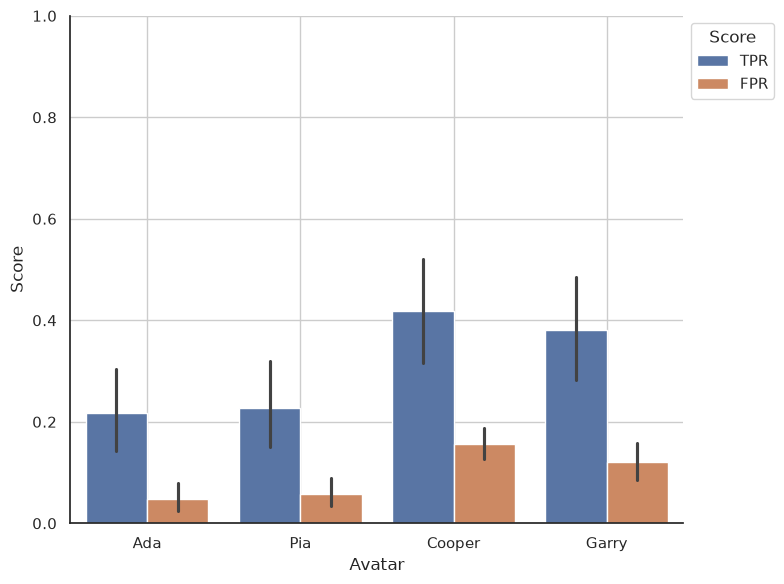

In [18]:
long_rates = pd.melt(df_comb[["avatar", "animation"] + RATES],
                     id_vars=["avatar", "animation"], var_name="Score")

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(long_rates, x="avatar", y="value", hue="Score",
            order=AVATAR_ORDER, ax=ax, legend=True)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine()
ax.set_ylim(0, 1)
ax.set_xlabel("Avatar")
ax.set_ylabel("Score")
ax.grid()
fig.tight_layout()
fig.savefig(
    os.path.join(RESULTS,
                 f"Figure2B_TPR_FPR_mean-barplot-CI_thr-{THRESHOLD}"
                 "_with-grid.svg"),
    dpi=DPI)
plt.show()

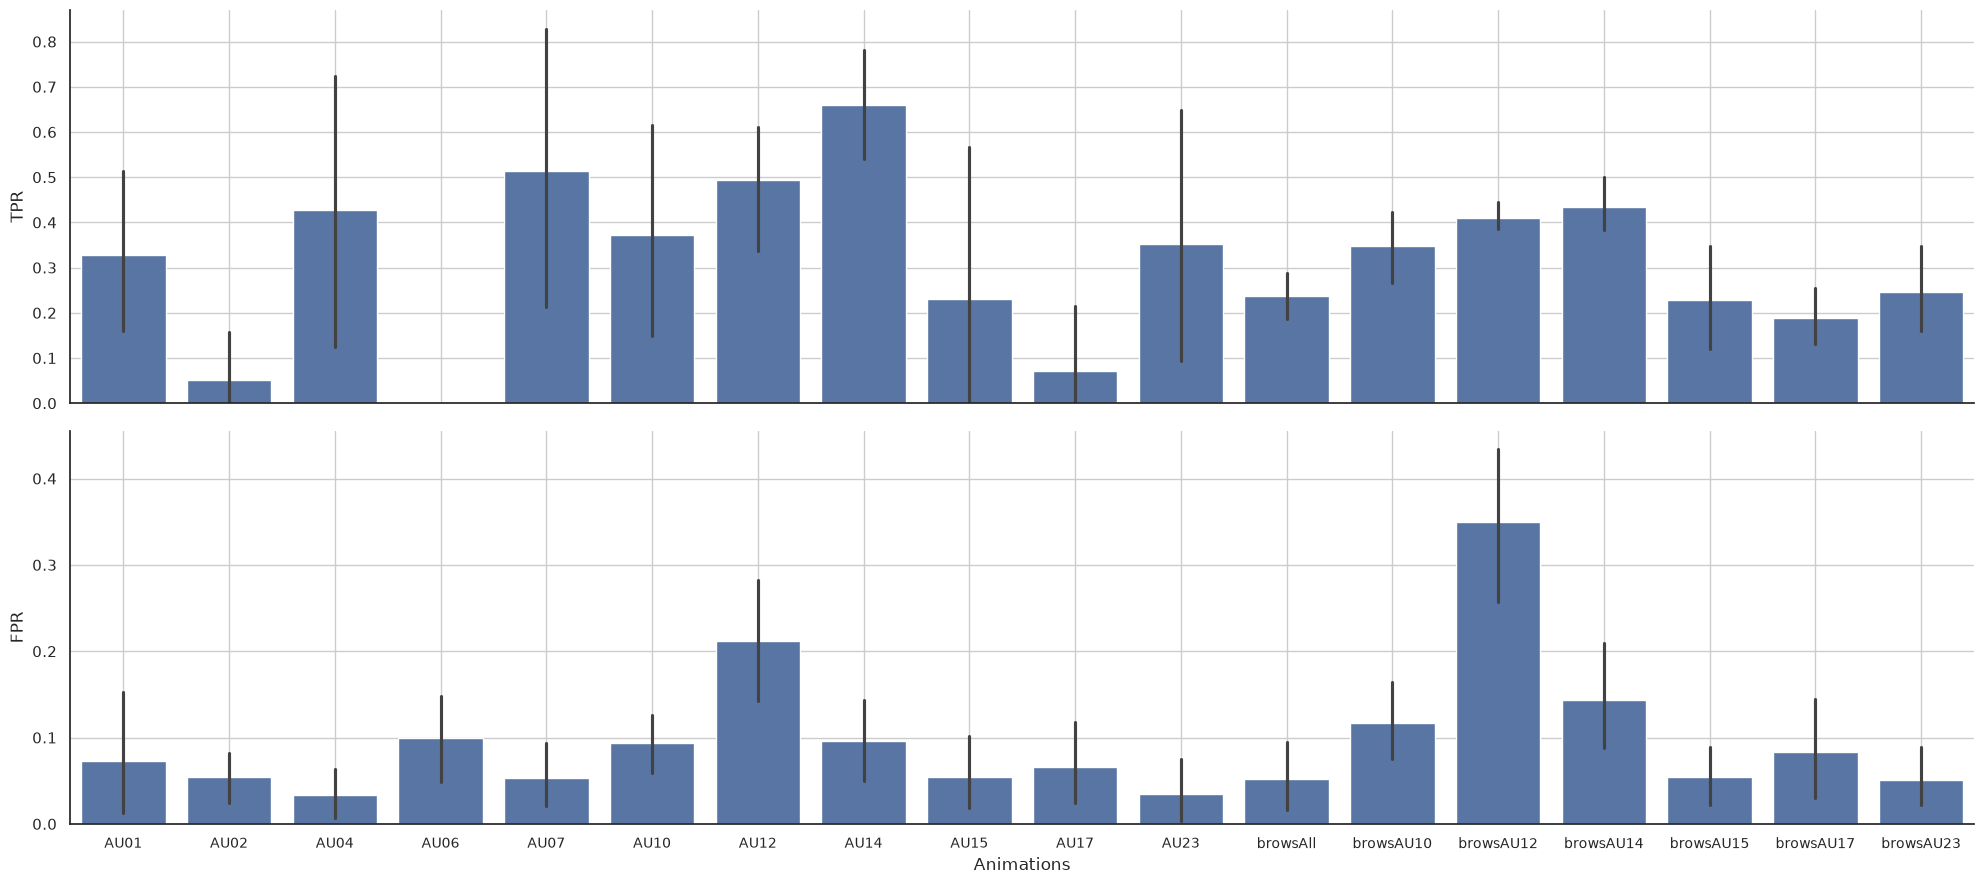

In [19]:
sns.set_style("white")
fig, axs = plt.subplots(len(RATES), 1, sharex=True, figsize=(20, 9))
for index, rate in enumerate(RATES):
    sns.barplot(df_comb, x="animation", y=rate, ax=axs[index])
    sns.despine()
    axs[index].set_xlabel("Animations", fontsize=LABEL_FONTSIZE)
    axs[index].set_ylabel(rate, fontsize=LABEL_FONTSIZE)
    axs[index].grid()
axs[-1].set_xticks(range(len(utils.ANIMATIONS)))
axs[-1].set_xticklabels(utils.ANIMATIONS, fontsize=TICK_FONTSIZE)
fig.tight_layout()
fig.savefig(
    os.path.join(RESULTS,
                 "Figure2C_TPR_FPR_barplot_mean_ci_grid.svg"), dpi=DPI)
plt.show()